# 00 · Exploración guiada (Hito 1)
Reportes diarios de JHU CSSE, enero a junio de 2020, leídos directamente desde el repositorio


## 1 · Primer reporte: `01-22-2020.csv`
Antes de unir todo, miramos un solo archivo para conocer el formato original.

In [1]:
import pandas as pd

BASE = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_daily_reports/"
)

primer_reporte = pd.read_csv(BASE + "01-22-2020.csv")

display(primer_reporte.head())
print(f"Filas: {primer_reporte.shape[0]} | Columnas: {primer_reporte.shape[1]}")
print("\nTipos de datos:")
print(primer_reporte.dtypes)
print("\nPaíses en el primer reporte:", primer_reporte["Country/Region"].nunique())


,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


Filas: 76 | Columnas: 6

Tipos de datos:
Province/State     object
Country/Region     object
Last Update        object
Confirmed         float64
Deaths            float64
Recovered         float64
dtype: object

Países en el primer reporte: 22


**Qué vemos:** 76 filas y 6 columnas, con 22 países o entidades (31 filas son provincias de China), y nombres del esquema 1 (`Province/State`, `Country/Region`, `Last Update`).
`Last Update` llega como texto (`object` en pandas 2, `str` en pandas 3), no como fecha. `Confirmed`, `Deaths` y `Recovered` son `float64`
aunque son conteos: pandas usa `float` porque hay celdas vacías (NaN) y un `int` normal no admite NaN.

### Nulos del Primer reporte

In [2]:
print(primer_reporte.isna().sum())

Province/State    12
Country/Region     0
Last Update        0
Confirmed         10
Deaths            37
Recovered         37
dtype: int64


**Qué significan:**
- `Province/State` (12): el país informa como un todo, sin provincias (ej. Japón, Tailandia). No es un error.
- `Confirmed` (10), `Deaths` y `Recovered` (37 cada una): JHU dejaba la celda **vacía cuando no había casos
  informados** (ej. Gansu). Es "no informado", no un dato perdido, y no se imputa.

## 2 · Unir enero a junio de 2020 y estandarizar columnas

Leemos los 161 reportes (22-ene → 30-jun). En este período aparecen dos cambios de esquema: el 1-mar llegan Latitude/Longitude (esquema 2) y el 22-mar cambia todo el formato (esquema 3: FIPS, Admin2, Lat, Long_, Combined_Key…).

In [3]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd

# Leemos directo desde el repositorio de JHU (raw), sin descargar archivos.
BASE = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_daily_reports/"
)

RENOMBRAR = {
    "Province/State": "province_state", "Province_State": "province_state",
    "Country/Region": "country_region", "Country_Region": "country_region",
    "Last Update": "last_update", "Last_Update": "last_update",
    "Latitude": "lat", "Lat": "lat", "Longitude": "long", "Long_": "long",
    "Incidence_Rate": "incident_rate", "Incident_Rate": "incident_rate",
    "Case-Fatality_Ratio": "case_fatality_ratio", "Case_Fatality_Ratio": "case_fatality_ratio",
}

def leer_reporte(fecha):
    nombre = fecha.strftime("%m-%d-%Y") + ".csv"   
    t = pd.read_csv(BASE + nombre).rename(columns=RENOMBRAR)
    t.columns = t.columns.str.lower()
    t["fecha_reporte"] = fecha                     
    return t

# los reportes parten el 22-ene-2020 
fechas = pd.date_range("2020-01-22", "2020-06-30", freq="D")

# 10 lecturas en paralelo
with ThreadPoolExecutor(max_workers=10) as ex:
    df = pd.concat(list(ex.map(leer_reporte, fechas)), ignore_index=True)

print(f"Reportes leídos: {len(fechas)} | filas: {df.shape[0]} | columnas: {df.shape[1]}")
display(df.head())


Reportes leídos: 161 | filas: 350945 | columnas: 15


,province_state,country_region,last_update,confirmed,deaths,recovered,fecha_reporte,lat,long,fips,admin2,active,combined_key,incident_rate,case_fatality_ratio
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN,2020-01-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Normalización de nombres de país 
JHU cambió cómo escribía algunos países (`Mainland China` → `China`, `South Korea` → `Korea, South`).
Además, algunos territorios partieron como si fueran países y luego pasaron a ser provincias
de otro (por ejemplo `Hong Kong` → provincia de `China`). Si no los unificamos, un mismo país
queda partido en dos y sus casos se cuentan mal.

In [4]:
PAIS = {
    " Azerbaijan": "Azerbaijan", "Bahamas, The": "Bahamas", "The Bahamas": "Bahamas",
    "Cape Verde": "Cabo Verde", "Czech Republic": "Czechia", "East Timor": "Timor-Leste",
    "Gambia, The": "Gambia", "The Gambia": "Gambia", "Iran (Islamic Republic of)": "Iran",
    "Ivory Coast": "Cote d'Ivoire", "Mainland China": "China", "Republic of Ireland": "Ireland",
    "Republic of Korea": "Korea, South", "South Korea": "Korea, South",
    "Republic of Moldova": "Moldova", "Republic of the Congo": "Congo (Brazzaville)",
    "Russian Federation": "Russia", "Taiwan": "Taiwan*", "Taipei and environs": "Taiwan*",
    "Vatican City": "Holy See", "Viet Nam": "Vietnam",
    "Palestine": "West Bank and Gaza", "occupied Palestinian territory": "West Bank and Gaza",
    "North Ireland": "United Kingdom", "Others": "Diamond Princess", "Cruise Ship": "Diamond Princess",
}

# Territorios que primero venían como "país" y después como provincia de otro país.
TERRITORIO = {
    "Hong Kong": "China", "Hong Kong SAR": "China", "Macau": "China", "Macao SAR": "China",
    "Puerto Rico": "US", "Guam": "US",
    "Aruba": "Netherlands", "Curacao": "Netherlands",
    "Cayman Islands": "United Kingdom", "Channel Islands": "United Kingdom",
    "Gibraltar": "United Kingdom", "Jersey": "United Kingdom", "Guernsey": "United Kingdom",
    "Faroe Islands": "Denmark", "Greenland": "Denmark",
    "French Guiana": "France", "Guadeloupe": "France", "Martinique": "France", "Mayotte": "France",
    "Reunion": "France", "Saint Barthelemy": "France", "Saint Martin": "France", "St. Martin": "France",
}

es_territorio = df["country_region"].isin(TERRITORIO)
df.loc[es_territorio, "province_state"] = df.loc[es_territorio, "country_region"]
df.loc[es_territorio, "country_region"] = df.loc[es_territorio, "country_region"].map(TERRITORIO)
df["country_region"] = df["country_region"].replace(PAIS)

# Control: ningún nombre debería quedar "huérfano" (existir antes pero no al 30-jun).
paises_fin = set(df.loc[df["fecha_reporte"] == "2020-06-30", "country_region"])
print("Nombres sin equivalente al 30-jun:", sorted(set(df["country_region"]) - paises_fin))


Nombres sin equivalente al 30-jun: []


### last_update a formato AAAA-MM-DD
`last_update` viene con dos formatos mezclados (`1/22/2020 17:00` y `2020-07-01 04:33:52`).

In [5]:
df["last_update"] = pd.to_datetime(df["last_update"], format="mixed").dt.normalize()

# Observación de calidad : hay filas de reportes de 2020 actualizadas mucho después.
print("last_update mínimo:", df["last_update"].min().date(), "| máximo:", df["last_update"].max().date())
df[["fecha_reporte", "last_update"]].head()


last_update mínimo: 2020-01-22 | máximo: 2021-04-02


,fecha_reporte,last_update
0,2020-01-22,2020-01-22
1,2020-01-22,2020-01-22
2,2020-01-22,2020-01-22
3,2020-01-22,2020-01-22
4,2020-01-22,2020-01-22


In [6]:
import numpy as np

condiciones = [
    df["fecha_reporte"] < "2020-03-01",   # esquema 1
    df["fecha_reporte"] < "2020-03-22",   # esquema 2
    df["fecha_reporte"] < "2020-05-29",   # esquema 3
    df["fecha_reporte"] < "2020-11-09",   # esquema 4
]
df["esquema"] = np.select(condiciones, [1, 2, 3, 4], default=5)   # desde el 9-nov-2020: esquema 5

df["esquema"].value_counts().sort_index()

esquema
1      4242
2      5555
3    217486
4    123662
Name: count, dtype: int64

In [7]:
df.shape


(350945, 16)

In [8]:
df.describe()


,last_update,confirmed,deaths,recovered,fecha_reporte,lat,long,fips,active,incident_rate,case_fatality_ratio,esquema
count,350945,350917.000000,350513.000000,350560.000000,350945,340251.000000,340251.000000,295838.000000,341148.000000,121132.000000,121478.000000,350945.000000
mean,2020-05-11 21:56:58.412571392,1327.528008,84.792573,548.818445,2020-05-11 04:37:47.965636096,35.996244,-75.464802,31270.730903,831.110410,371.874182,3.653157,3.312365
min,2020-01-22 00:00:00,0.000000,0.000000,0.000000,2020-01-22 00:00:00,-71.949900,-175.198200,66.000000,0.000000,0.000000,0.000000,1.000000
25%,2020-04-16 00:00:00,5.000000,0.000000,0.000000,2020-04-16 00:00:00,33.590350,-96.209268,18147.000000,5.000000,67.664721,0.000000,3.000000
50%,2020-05-14 00:00:00,30.000000,1.000000,0.000000,2020-05-13 00:00:00,37.851064,-87.310940,29163.000000,26.000000,174.842067,1.775912,3.000000
75%,2020-06-08 00:00:00,191.000000,6.000000,0.000000,2020-06-07 00:00:00,41.686254,-79.775048,46051.000000,157.000000,422.896661,5.112311,4.000000
max,2021-04-02 00:00:00,405843.000000,48628.000000,720631.000000,2020-06-30 00:00:00,72.000000,178.065000,99999.000000,249015.000000,13160.226870,5400.000000,4.000000
std,NaN,9807.780651,995.128516,8030.288541,NaN,12.216757,50.091787,17059.098046,6272.553427,649.378528,24.625718,0.564779


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350945 entries, 0 to 350944
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   province_state       328821 non-null  object        
 1   country_region       350945 non-null  object        
 2   last_update          350945 non-null  datetime64[ns]
 3   confirmed            350917 non-null  float64       
 4   deaths               350513 non-null  float64       
 5   recovered            350560 non-null  float64       
 6   fecha_reporte        350945 non-null  datetime64[ns]
 7   lat                  340251 non-null  float64       
 8   long                 340251 non-null  float64       
 9   fips                 295838 non-null  float64       
 10  admin2               296224 non-null  object        
 11  active               341148 non-null  float64       
 12  combined_key         341148 non-null  object        
 13  incident_rate 

## 3 · Valores nulos por columna

In [10]:
print(df.isna().sum())

province_state          22124
country_region              0
last_update                 0
confirmed                  28
deaths                    432
recovered                 385
fecha_reporte               0
lat                     10694
long                    10694
fips                    55107
admin2                  54721
active                   9797
combined_key             9797
incident_rate          229813
case_fatality_ratio    229467
esquema                     0
dtype: int64


In [11]:
df.isna().groupby(df["esquema"]).sum().T


esquema,1,2,3,4
province_state,1148,2437,12661,5878
country_region,0,0,0,0
last_update,0,0,0,0
confirmed,28,0,0,0
deaths,432,0,0,0
recovered,385,0,0,0
fecha_reporte,0,0,0,0
lat,4242,63,3859,2530
long,4242,63,3859,2530
fips,4242,5555,22695,22615


### Qué significan los nulos en este conjunto
La mayoría **no son datos perdidos**: son columnas que todavía no existían o que no aplican a esa fila.
Por eso no se imputan.

| Columna | Nulos | Significado |
|---|---|---|
| `province_state` | ~22 mil | El país informa como un todo, sin subdivisión (ej. Chile hasta el 19-may). No es un error. |
| `confirmed`, `deaths`, `recovered` | 28 / 432 / 385 | Solo en el esquema 1 (enero–febrero): JHU dejaba la celda vacía cuando no había casos informados (ej. Gansu el 22-ene). |
| `lat`, `long` | ~10,7 mil | Todo el esquema 1 (la columna no existía) más territorios sin coordenadas (ej. filas «Unknown» o «Recovered»). |
| `fips`, `admin2` | ~55 mil | Códigos de **condado de EE.UU.**: no existen antes del 22-mar y no aplican a ningún otro país. |
| `active`, `combined_key` | ~9,8 mil | Columnas creadas en el esquema 3 (22-mar): antes no existían. |
| `incident_rate`, `case_fatality_ratio` | ~230 mil | Columnas del esquema 4 (desde el 29-may): no existen en el 65 % de las filas del período. |

**Conclusión:** solo los nulos de conteo del esquema 1 son "dato faltante" real, y son pocos (menos de 0,2 % de las filas).

## 4 · De acumulados a casos diarios
Los reportes traen **acumulados**: los casos nuevos se calculan restando el día anterior.

**Por qué no restar fila contra fila :** EE.UU. tiene miles de filas por día y Chile 17 desde el 20-may-2020.
Al ordenar por país y fecha, `diff()` restaba una provincia contra otra.

**Qué hacemos:** primero sumamos todas las filas del país por día y después
aplicamos `diff()`. Así el paso de Chile nacional → 16 regiones no produce saltos. El primer día se rellena con
`confirmed`, porque antes del primer reporte el país tenía 0 casos.

In [12]:
# Nivel PAÍS: sumar primero, diff después
pais = (
    df.groupby(["country_region", "fecha_reporte"], as_index=False)[["confirmed", "deaths"]]
      .sum(min_count=1)                        # min_count=1: si todo es NaN, queda NaN (no 0)
      .sort_values(["country_region", "fecha_reporte"])
)
g = pais.groupby("country_region")
pais["casos_nuevos"] = g["confirmed"].diff()
pais["fallecidos_nuevos"] = g["deaths"].diff()

primer = g.cumcount() == 0                     # primera fila de cada país
pais.loc[primer, "casos_nuevos"] = pais.loc[primer, "confirmed"]
pais.loc[primer, "fallecidos_nuevos"] = pais.loc[primer, "deaths"]

# Control: la suma de los diarios de Chile debe dar su acumulado al 30-jun
chile = pais[pais["country_region"] == "Chile"].set_index("fecha_reporte")
print("Chile · suma de casos nuevos:", int(chile["casos_nuevos"].sum()),
      "| acumulado al 30-jun:", int(chile["confirmed"].iloc[-1]))

Chile · suma de casos nuevos: 279393 | acumulado al 30-jun: 279393


### Top 10 países al 30 de junio de 2020 
Para "casos acumulados al 30-jun" basta sumar `confirmed` de ese día por país.

In [13]:
top10 = (
    pais[pais["fecha_reporte"] == "2020-06-30"]
    .nlargest(10, "confirmed")[["country_region", "confirmed"]]
    .reset_index(drop=True)
)
top10


,country_region,confirmed
0,US,2653658.0
1,Brazil,1412669.0
2,Russia,646929.0
3,India,585493.0
4,United Kingdom,314157.0
5,Peru,285213.0
6,Chile,279393.0
7,Spain,249271.0
8,Italy,240578.0
9,Iran,227662.0


## 5 · Evolución de Chile (22-ene → 30-jun-2020)
Graficamos los **casos nuevos diarios** con su **media móvil de 7 días** (la media se calcula sobre los diarios, nunca sobre los acumulados).
Abajo, el acumulado como referencia.

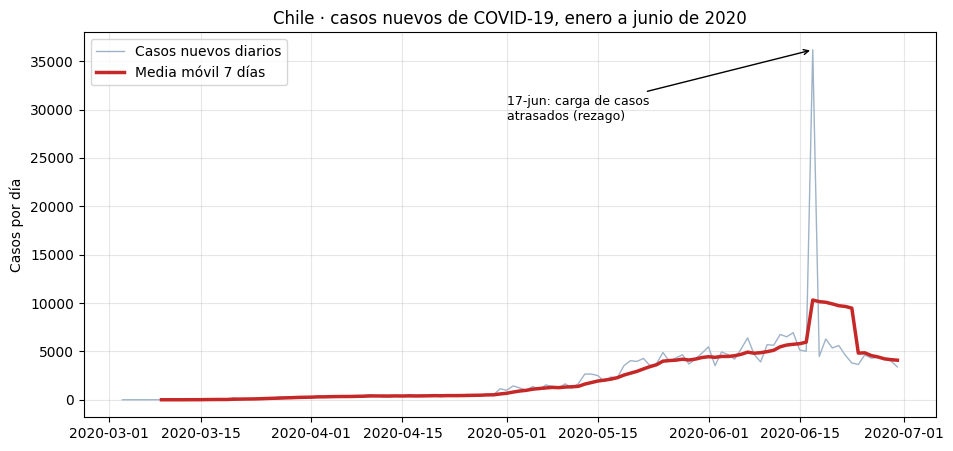

Primer caso: 2020-03-03
Acumulado al 30-jun: 279393
Peor día: 2020-06-17 con 36179 casos
Media móvil 7 días más alta: 2020-06-17 con 10310 casos/día


In [14]:
import matplotlib.pyplot as plt

chile = pais[pais["country_region"] == "Chile"].set_index("fecha_reporte")
chile["media_movil_7d"] = chile["casos_nuevos"].rolling(7).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(chile.index, chile["casos_nuevos"], color="#9fb3c8", lw=1, label="Casos nuevos diarios")
ax.plot(chile.index, chile["media_movil_7d"], color="#c62828", lw=2.5, label="Media móvil 7 días")
ax.annotate("17-jun: carga de casos\natrasados (rezago)",
            xy=(pd.Timestamp("2020-06-17"), chile.loc["2020-06-17", "casos_nuevos"]),
            xytext=(pd.Timestamp("2020-05-01"), chile["casos_nuevos"].max() * 0.8),
            arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_title("Chile · casos nuevos de COVID-19, enero a junio de 2020")
ax.set_ylabel("Casos por día")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()

print("Primer caso:", chile["confirmed"].gt(0).idxmax().date())
print("Acumulado al 30-jun:", int(chile["confirmed"].iloc[-1]))
print("Peor día:", chile["casos_nuevos"].idxmax().date(), "con", int(chile["casos_nuevos"].max()), "casos")
print("Media móvil 7 días más alta:", chile["media_movil_7d"].idxmax().date(),
    "con", round(chile["media_movil_7d"].max()), "casos/día")


La primera ola de Chile sube con fuerza desde mayo y se mantiene en torno a 5.000–6.000 casos diarios en junio.
El pico aislado del 17-jun (36.179) **no es un día real de contagios**: ese día se sumaron casos que no se habían informado antes.
Al observar la media móvil: el rezago la infla durante exactamente 7 días (la "meseta" de ~10.000 entre el 17 y el 23-jun) y luego cae de golpe.
Esa meseta es un artefacto del dato, no una ola: una alerta temprana ingenua se dispararía aquí. Es un problema de calidad.
El cambio a regiones del 20-may no produce saltos porque sumamos por país antes de calcular los diarios.

## 6 · Perfilado automático (ydata-profiling)
`minimal=True` omite los cálculos más pesados (correlaciones e interacciones), necesario con 350 mil filas.
El informe se guarda como `perfilado_ene_jun_2020.html`.

In [15]:
# En Colab hay que instalarlo una vez por sesión.
%pip install -q ydata-profiling


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: D:\codigos\UCSC\Trabajo_GD\Proyecto_GD\.venv\Scripts\python.exe -m pip install --upgrade pip


In [16]:
from ydata_profiling import ProfileReport

perfil = ProfileReport(df, title="Reportes JHU · enero a junio 2020", minimal=True)
perfil.to_file("perfilado_ene_jun_2020.html")
perfil.to_notebook_iframe()


C:\Users\mcvio\AppData\Local\Temp\ipykernel_15808\3593965207.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:00<00:02,  6.75it/s]

 38%|███▊      | 6/16 [00:00<00:00, 26.72it/s]

100%|██████████| 16/16 [00:00<00:00, 58.42it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [17]:
# Verificamos con código las cifras de las tres observaciones.
fallecidos_mayor = df[df["deaths"] > df["confirmed"]]
print("1) Filas con fallecidos > casos:", len(fallecidos_mayor),
      f"| con casos = 0: {(fallecidos_mayor['confirmed'] == 0).mean():.0%}")
print(fallecidos_mayor["country_region"].value_counts().head(3).to_string())
print("   Filas US 'Unassigned':", (fallecidos_mayor["admin2"] == "Unassigned").sum())

desde_esq3 = df["esquema"] >= 3
print(f"\n2) recovered = 0 desde el esquema 3: {(df.loc[desde_esq3, 'recovered'] == 0).mean():.0%} de las filas")

print(f"\n3) confirmed · mediana: {df['confirmed'].median():.0f} | máximo: {df['confirmed'].max():,.0f}"
      f" | asimetría: {df['confirmed'].skew():.1f}")

atraso = (df["last_update"] - df["fecha_reporte"]).dt.days
print(f"\nExtra) Filas con last_update más de 2 días después del reporte: {(atraso > 2).sum()}"
      f" | máximo: {df['last_update'].max().date()}")

1) Filas con fallecidos > casos: 1357 | con casos = 0: 85%
country_region
US                900
United Kingdom    397
Canada             57
   Filas US 'Unassigned': 759

2) recovered = 0 desde el esquema 3: 89% de las filas

3) confirmed · mediana: 30 | máximo: 405,843 | asimetría: 16.5

Extra) Filas con last_update más de 2 días después del reporte: 112 | máximo: 2021-04-02


### Tres observaciones del perfilado

1. **Más fallecidos que casos (consistencia).** En el informe, `case_fatality_ratio` (letalidad en %) llega a un **máximo de 5.400**
   y tiene la alerta *Skewed* (γ1 ≈ 154). Una letalidad sobre 100 % es imposible: solo ocurre cuando una fila tiene más fallecidos que casos.
   El código lo confirma: ~1.360 filas con `deaths > confirmed`, en el 85 % con casos = 0, casi todas de EE.UU. (filas `Unassigned`:
   fallecidos que aún no se asignaban a un condado) y del Reino Unido. Al sumar por país se compensa.
2. **`recovered` casi no se informa (completitud).** El informe da la alerta *Zeros*: **88,5 % de las filas tiene `recovered = 0`**.
   Viene de los condados de EE.UU., que no informan recuperados (el código muestra ~89 % desde el esquema 3).
   Un 0 aquí significa "no informado", no "nadie se recuperó": no usaremos esta columna para calcular casos activos.
3. **Distribución muy asimétrica (distribución).** En la ficha de `confirmed`: **mediana 30, máximo 405.843 y asimetría (Skewness) 16,5**;
   el informe además marca `deaths` y `recovered` como *highly skewed*. Conviven condados pequeños con países enteros:
   los promedios engañan, así que para comparar territorios usaremos tasas por 100.000 habitantes.

**Extra (oportunidad):** en la ficha de `last_update` el **máximo es 2021-04-02**, en datos de enero a junio de 2020. El código muestra
112 filas con `last_update` posterior a su fecha de reporte; la más tardía es de Alaska (reporte del 6-may-2020).
JHU corrigió datos viejos casi un año después: por eso la fecha del dato es `fecha_reporte`, nunca `last_update`.

## 7 · Pregunta propia y fuente externa
**P7:** ¿Los países que llegaron antes al 50 % de población con esquema completo tuvieron menos fallecidos
por 100.000 durante la ola de ómicron (1-dic-2021 a 31-mar-2022)?

- **Fuente externa:** Our World in Data, vacunación, leída desde
  `raw.githubusercontent.com/owid/covid-19-data/master/public/data/vaccinations/vaccinations.csv`.
- **Cruce:** `iso_code` de OWID con el código ISO3 de la tabla UID de JHU.
- **Fuente de apoyo:** Banco Mundial, % de población de 65 años o más y PIB per cápita 2021,
  para comparar países de edad e ingreso parecidos.
- **50 %** = `people_fully_vaccinated_per_hundred` ≥ 50.
- **Ventana de ómicron:** fija e igual para todos los países, 2021-12-01 → 2022-03-31.
- **Cautela:** correlación no es causalidad; los países que se vacunaron antes también suelen tener más ingreso, más testeo
  y otra estructura de edad, y todo eso cambia sus cifras de fallecidos.

**Dónde se responde:** `05_analisis`, sección 6 (número, gráfico e interpretación).